Retail_pivot Table(Total Amount & Mean Age):
                        Age            Total Amount       
Gender               Female       Male       Female   Male
Product Category                                          
Beauty            40.355422  40.390071        74830  68685
Clothing          43.166667  40.751412        81275  74305
Electronics       40.482353  42.976744        76735  80170

montly_sales trend
Month
January      36980
February     44060
March        28990
April        33870
May          53150
June         36715
July         35465
August       36960
September    23620
October      46580
November     34920
December     44690
Name: Total Amount, dtype: int64


C:\Users\soheil\AppData\Local\Temp\ipykernel_12860\958483905.py:31: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(ax=axes[0], data=df_retail, x="Product Category", y="Total Amount", hue="Gender", estimator=sum, ci=None, palette="Set1")


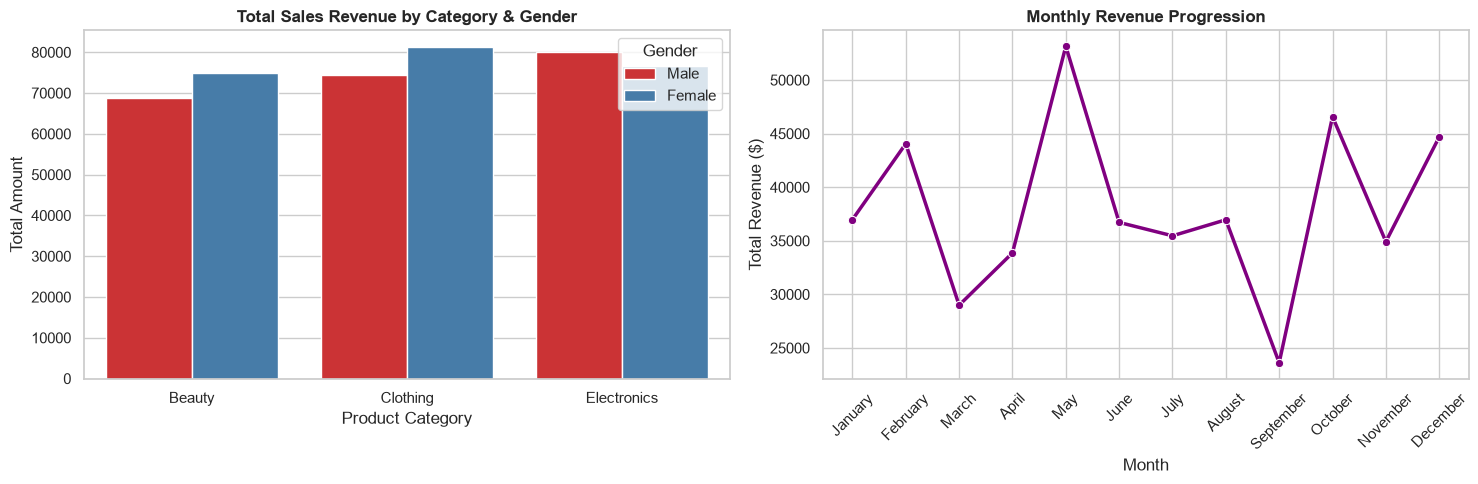

In [4]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df_retail=pd.read_csv("retail_sales_dataset.csv")

df_retail["Date"]=pd.to_datetime(df_retail["Date"])
df_retail["Month"]=df_retail["Date"].dt.month_name()
df_retail["Days-Of-Week"]=df_retail["Date"].dt.day_name()
df_retail.head()



retail_pivot=df_retail.pivot_table(
    index="Product Category",
    columns="Gender",
    values=["Total Amount", "Age"],
    aggfunc={"Total Amount": "sum", "Age": "mean"}
)
print("Retail_pivot Table(Total Amount & Mean Age):")
print(retail_pivot)

monthly_sales=df_retail.groupby("Month")["Total Amount"].sum().reindex([
    "January", "February", "March", "April", "May", 'June', 'July', 'August', 'September','October' , 'November','December'])
print("\nmontly_sales trend")
print(monthly_sales)

sns.set_theme(style="whitegrid")
fig, axes=plt.subplots(1,2, figsize=(15,5))
sns.barplot(ax=axes[0], data=df_retail, x="Product Category", y="Total Amount", hue="Gender", estimator=sum, ci=None, palette="Set1")
axes[0].set_title("Total Sales Revenue by Category & Gender", fontsize=12, fontweight='bold')
sns.lineplot(ax=axes[1], x=monthly_sales.index, y=monthly_sales.values, color='purple', marker='o', linewidth=2.5)
axes[1].set_title('Monthly Revenue Progression', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Total Revenue ($)')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()